# Car Breakdown Prediction

In deze notebook analyseren we de trainingsdata en bouwen we een eerste model om te voorspellen of een auto binnen 30 dagen kapot gaat.

De notebook bevat:
- een korte data-analyse
- voorbereiding van de data
- een Random Forest model
- evaluatie van het model
- voorspellingen op de testdata
- het maken van een submission file

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

## Trainingsdata inladen
We laden eerst de trainingsdata in.

In [2]:
train = pd.read_csv("../train_CarBreakDown.csv")
train.head()

,id,vehicle_brand,vehicle_age_years,mileage_km,engine_hours,last_service_km_ago,oil_quality_pct,avg_trip_length_km,weather_exposure,fuel_type,cleanliness_score,driver_satisfaction_score,tyre_type,breakdown_next_30_days
0,959,Toyota,20.0,494744.972722,9700.481467,1672.048445,61.664556,30.362090,high,petrol,68.117833,8.559011,NaN,0
1,804,Toyota,0.0,38376.684834,1650.726428,21.269170,23.370666,2.500801,high,hybrid,69.294736,9.838274,NaN,0
2,1304,Hyundai,1.0,188558.432414,6678.958321,11726.320455,25.491428,41.692205,medium,hybrid,47.223966,5.842726,winter,0
3,268,Toyota,5.0,92828.113285,2986.923461,1845.744691,54.060416,6.464345,high,diesel,72.246829,4.719607,winter,0
4,47,NaN,10.0,118366.394287,4222.193011,12551.181627,65.766074,47.159242,low,diesel,77.368891,6.724967,winter,0


## Verkennen van de dataset
We bekijken de grootte van de dataset, de kolommen en eventuele ontbrekende waarden.

In [3]:
print("Shape:", train.shape)
print()
print(train.columns)
print()
print(train.isnull().sum())

Shape: (1050, 14)

Index(['id', 'vehicle_brand', 'vehicle_age_years', 'mileage_km',
       'engine_hours', 'last_service_km_ago', 'oil_quality_pct',
       'avg_trip_length_km', 'weather_exposure', 'fuel_type',
       'cleanliness_score', 'driver_satisfaction_score', 'tyre_type',
       'breakdown_next_30_days'],
      dtype='str')

id                            0
vehicle_brand                21
vehicle_age_years            16
mileage_km                   17
engine_hours                 15
last_service_km_ago          10
oil_quality_pct              36
avg_trip_length_km           12
weather_exposure             13
fuel_type                    14
cleanliness_score            55
driver_satisfaction_score    13
tyre_type                    17
breakdown_next_30_days        0
dtype: int64


## Verdeling van de target
De kolom `breakdown_next_30_days` is de target:
- 0 = geen breakdown
- 1 = wel breakdown

In [4]:
print(train["breakdown_next_30_days"].value_counts())
print()
print(train["breakdown_next_30_days"].value_counts(normalize=True) * 100)

breakdown_next_30_days
0    874
1    176
Name: count, dtype: int64

breakdown_next_30_days
0    83.238095
1    16.761905
Name: proportion, dtype: float64


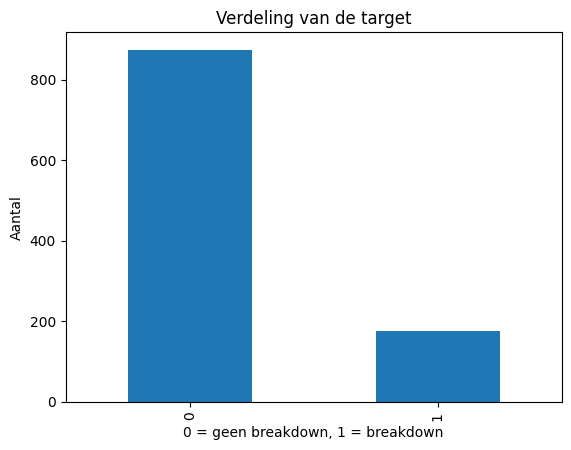

In [5]:
train["breakdown_next_30_days"].value_counts().plot(kind="bar")
plt.title("Verdeling van de target")
plt.xlabel("0 = geen breakdown, 1 = breakdown")
plt.ylabel("Aantal")
plt.show()

## Enkele eenvoudige analyses
We bekijken of bepaalde variabelen verschillen tussen auto's die wel of niet kapot gaan.

In [6]:
train.groupby("fuel_type")["breakdown_next_30_days"].mean().sort_values()

fuel_type
other       0.150000
hybrid      0.161290
diesel      0.166667
petrol      0.174713
electric    0.185185
Name: breakdown_next_30_days, dtype: float64

In [7]:
train.groupby("weather_exposure")["breakdown_next_30_days"].mean().sort_values()

weather_exposure
other     0.142857
medium    0.149533
low       0.174479
high      0.200980
Name: breakdown_next_30_days, dtype: float64

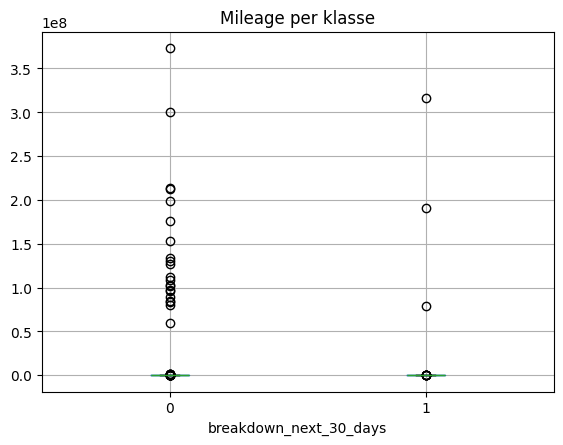

In [8]:
train.boxplot(column="mileage_km", by="breakdown_next_30_days")
plt.title("Mileage per klasse")
plt.suptitle("")
plt.show()

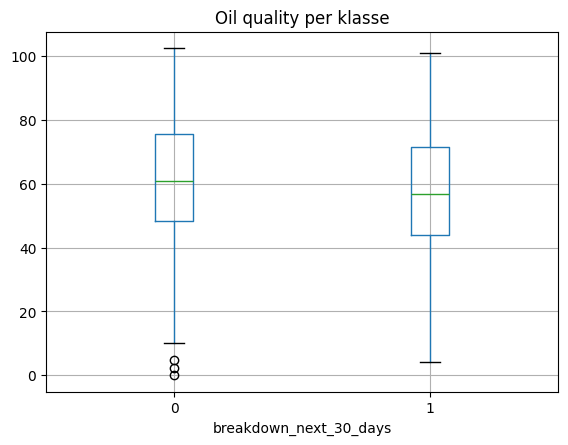

In [9]:
train.boxplot(column="oil_quality_pct", by="breakdown_next_30_days")
plt.title("Oil quality per klasse")
plt.suptitle("")
plt.show()

## Korte conclusie van de EDA
De dataset bevat zowel numerieke als categorische variabelen.  
De target is niet gelijk verdeeld: er zijn meer auto's zonder breakdown dan met breakdown.  
Variabelen zoals mileage, oil quality en weather exposure lijken nuttig voor het model.

## Data voorbereiden
We splitsen de data in features (`X`) en target (`y`).

De kolom `id` gebruiken we niet als input voor het model.
Categorische kolommen zetten we om met `get_dummies()`.

In [10]:
X = train.drop(["id", "breakdown_next_30_days"], axis=1)
y = train["breakdown_next_30_days"]

X = pd.get_dummies(X)

print(X.shape)
print(y.shape)

(1050, 30)
(1050,)


## Train en validatie
We splitsen de trainingsdata in een trainset en validatieset.

In [11]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## Random Forest model
We gebruiken een Random Forest als baseline model.

In [12]:
model = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42
)

model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

## Evaluatie
We evalueren het model op de validatieset.

Omdat de dataset onevenwichtig is, gebruiken we kansen (`predict_proba`) en zetten we daarna een threshold.

In [13]:
val_probs = model.predict_proba(X_val)[:, 1]
val_predictions = (val_probs >= 0.40).astype(int)

print("Accuracy:", accuracy_score(y_val, val_predictions))
print()
print("Confusion matrix:")
print(confusion_matrix(y_val, val_predictions))

Accuracy: 0.8333333333333334

Confusion matrix:
[[168   7]
 [ 28   7]]


## Testdata inladen
Nu laden we de testdata in en passen we dezelfde preprocessing toe.

In [14]:
test = pd.read_csv("../test_CarBreakDown.csv")
test.head()

,id,vehicle_brand,vehicle_age_years,mileage_km,engine_hours,last_service_km_ago,oil_quality_pct,avg_trip_length_km,weather_exposure,fuel_type,cleanliness_score,driver_satisfaction_score,tyre_type
0,1356,Volkswagen,11.0,227101.296523,7111.496798,31877.398870,45.316195,11.303376,medium,petrol,86.002184,6.789866,winter
1,889,Kia,5.0,131740.074640,4384.690626,24086.715660,55.920468,21.079253,high,petrol,99.964621,9.780574,winter
2,1190,Hyundai,20.0,172283.708707,5997.321760,1087.406667,69.344516,2.827233,medium,diesel,NaN,6.525088,summer
3,122,Toyota,14.0,125092.331956,3710.026613,6919.769411,55.607730,15.947450,NaN,diesel,82.986605,5.850790,all-season
4,1101,Ford,19.0,207068.220620,7152.178785,8102.143623,78.170298,31.696566,low,electric,92.119900,7.954186,summer


In [15]:
test_ids = test["id"]

test_features = test.drop("id", axis=1)
test_features = pd.get_dummies(test_features)
test_features = test_features.reindex(columns=X.columns, fill_value=0)

## Voorspellingen maken
We gebruiken hetzelfde model op de testdata.

In [16]:
test_probs = model.predict_proba(test_features)[:, 1]
test_predictions = (test_probs >= 0.50).astype(int)

In [17]:
submission = pd.DataFrame({
    "id": test_ids,
    "breakdown_next_30_days": test_predictions
})

submission.head()

,id,breakdown_next_30_days
0,1356,0
1,889,0
2,1190,0
3,122,0
4,1101,0


In [18]:
submission["breakdown_next_30_days"].value_counts()

breakdown_next_30_days
0    449
1      1
Name: count, dtype: int64

In [19]:
submission.to_csv("2submission.csv", index=False)
print("submission.csv is opgeslagen.")

submission.csv is opgeslagen.


## Besluit
We hebben eerst de data kort geanalyseerd en daarna een Random Forest model gebouwd.

Daarna hebben we:
- de data voorbereid
- het model getraind
- het model geëvalueerd
- voorspellingen gemaakt voor de testdata
- een submission file gemaakt voor Kaggle

Deze notebook geeft een eenvoudige maar werkende basis voor de opdracht.